In [9]:
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
df=pd.read_csv("avis-clients-projet/data/raw/sample_reviews.csv")
df.shape

(10, 7)

In [11]:
print(df.isnull().sum())
print(df["Time"])

Id           0
ProductId    0
UserId       0
Score        0
Time         0
Summary      0
Text         0
dtype: int64
0    1303862400
1    1346976000
2    1219017600
3    1307923200
4    1350777600
5    1342051200
6    1334707200
7    1318892800
8    1357862400
9    1295049600
Name: Time, dtype: int64


In [12]:
df['Date']=pd.to_datetime(df['Time'],unit='s')

In [13]:
import re
def clean_text(text:str)->str:
    text=text.lower()
    text=re.sub(r"[^a-zA-Z\s]"," ",text)
    text=re.sub(r"\s+"," ",text).strip()
    return text

In [14]:
df['clean_Text']=df['Text'].apply(clean_text)
print(df['clean_Text'])

0    i have bought several of the vitality canned d...
1    product arrived labeled as jumbo salted peanut...
2    if you are looking for the secret ingredient i...
3    great taffy at a great price there was a wide ...
4    i got a wild hair for taffy and ordered this f...
5    this is a very bad food my dog hated it and wo...
6    this is a great little book to read along with...
7    it was okay not the best but not bad either i ...
8    my dog loves it and the quality seems great wi...
9    worst purchase ever the product was damaged wh...
Name: clean_Text, dtype: object


Score
1    3
2    1
3    1
4    1
5    4
Name: count, dtype: int64


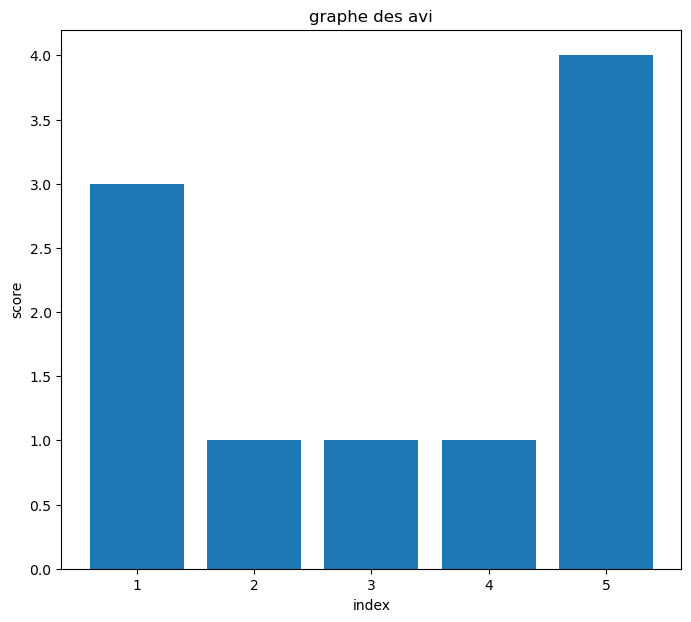

In [15]:
#tracons les avis
nbr_de_avi=df['Score'].value_counts().sort_index()
print(nbr_de_avi)
plt.figure(figsize=(8,7))
plt.bar(nbr_de_avi.index,nbr_de_avi.values)
plt.xlabel('index')
plt.ylabel('score')
plt.title("graphe des avi")
plt.show()

Month
April        2
August       1
January      2
July         1
June         1
October      2
September    1
dtype: int64


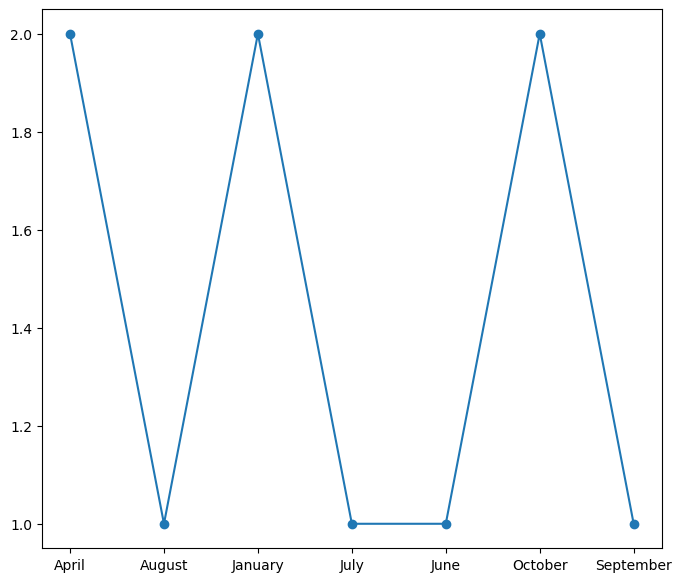

In [16]:
#les avis dans les temps
df['Month']=df['Date'].dt.month_name()
avi_month=df.groupby('Month').size()
print(avi_month)
plt.figure(figsize=(8,7))
plt.plot(avi_month.index.astype(str), avi_month.values, marker='o')

In [17]:
df_reel=pd.read_csv('avis-clients-projet/data/raw/Reviews.csv')

In [18]:
df_reel['Date']=pd.to_datetime(df_reel['Time'],unit='s')
df_reel[['Time','Date']].head()

,Time,Date
0,1303862400,2011-04-27
1,1346976000,2012-09-07
2,1219017600,2008-08-18
3,1307923200,2011-06-13
4,1350777600,2012-10-21


In [19]:
print(df_reel.shape)

(568454, 11)


In [20]:
val_score=df_reel['Score'].value_counts().sort_index()
print(val_score)

Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64


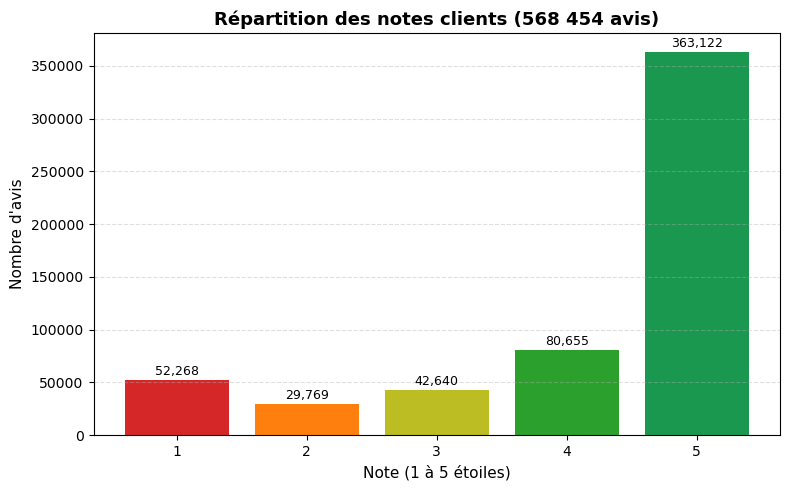

In [21]:
couleurs = ['#d62728', '#ff7f0e', '#bcbd22', '#2ca02c', '#1a9850']
plt.figure(figsize=(8, 5))
barres = plt.bar(val_score.index, val_score.values, color=couleurs)

# Afficher le nombre exact au-dessus de chaque barre
for barre in barres:
    hauteur = barre.get_height()
    plt.text(barre.get_x() + barre.get_width()/2, hauteur + 5000,
              f'{int(hauteur):,}', ha='center', fontsize=9)

plt.xlabel('Note (1 à 5 étoiles)', fontsize=11)
plt.ylabel("Nombre d'avis", fontsize=11)
plt.title('Répartition des notes clients (568 454 avis)', fontsize=13, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.xticks(val_score.index)
plt.tight_layout()
plt.show()

In [22]:
df_reel['clean_Text']=df_reel['Text'].apply(clean_text)
df_reel['clean_Text'].head()

0    i have bought several of the vitality canned d...
1    product arrived labeled as jumbo salted peanut...
2    this is a confection that has been around a fe...
3    if you are looking for the secret ingredient i...
4    great taffy at a great price there was a wide ...
Name: clean_Text, dtype: object

In [23]:
#evolution des avis dans le temps 
df_reel['month']=df_reel['Date'].dt.to_period('M')
avis_mois=df_reel.groupby('month').size()
avis_mois.tail(20)

month
2011-03    12494
2011-04    11531
2011-05    11029
2011-06    11501
2011-07    12299
2011-08    13957
2011-09    14803
2011-10    16623
2011-11    16235
2011-12    19038
2012-01    21686
2012-02    18797
2012-03    19780
2012-04    18924
2012-05    19435
2012-06    18113
2012-07    19847
2012-08    19834
2012-09    21912
2012-10    20331
Freq: M, dtype: int64

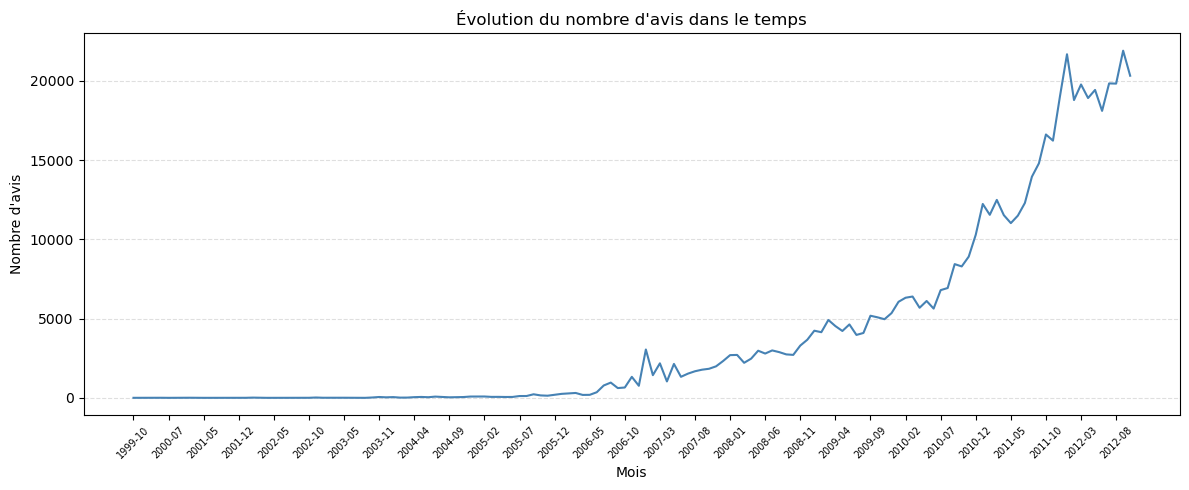

In [24]:
plt.figure(figsize=(12, 5))
plt.plot(avis_mois.index.astype(str), avis_mois.values, color='steelblue')
plt.xlabel('Mois')
plt.ylabel("Nombre d'avis")
plt.title("Évolution du nombre d'avis dans le temps")
position=range(0,len(avis_mois),5)
labels=[str(avis_mois.index[i]) for i in position]
plt.xticks(position,labels,rotation=45, fontsize=7)

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [25]:
#Analyse des sentiments 
sentiment_par_mois=df_reel.groupby('month')['Score'].mean()
sentiment_par_mois

month
1999-10    5.000000
1999-12    5.000000
2000-01    3.500000
2000-02    4.000000
2000-06    5.000000
             ...   
2012-06    4.085850
2012-07    4.147781
2012-08    4.123626
2012-09    4.119934
2012-10    4.178889
Freq: M, Name: Score, Length: 143, dtype: float64

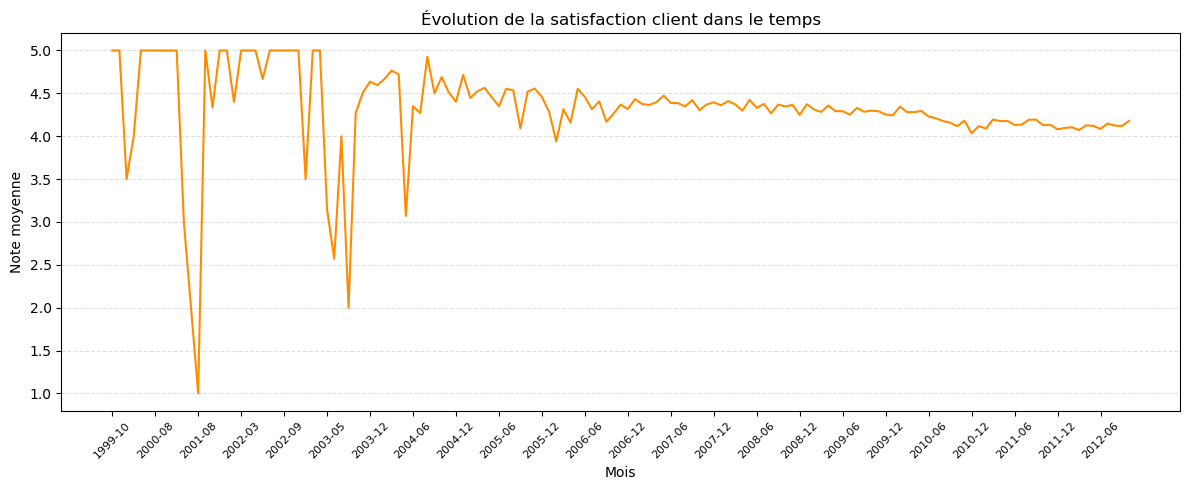

In [26]:
plt.figure(figsize=(12, 5))
plt.plot(sentiment_par_mois.index.astype(str), sentiment_par_mois.values, color='darkorange')

positions = range(0, len(sentiment_par_mois), 6)
labels = [str(sentiment_par_mois.index[i]) for i in positions]
plt.xticks(positions, labels, rotation=45, fontsize=8)

plt.xlabel('Mois')
plt.ylabel('Note moyenne')
plt.title('Évolution de la satisfaction client dans le temps')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [27]:
#la partie NLP
#Etape 1
def score_to_sentiment(score):
    if score<=2:
        return 'negatif'
    elif score>=4:
        return 'positif'
    else:
        return 'neutre'

In [28]:
df_reel['Sentiment']=df_reel['Score'].apply(score_to_sentiment)

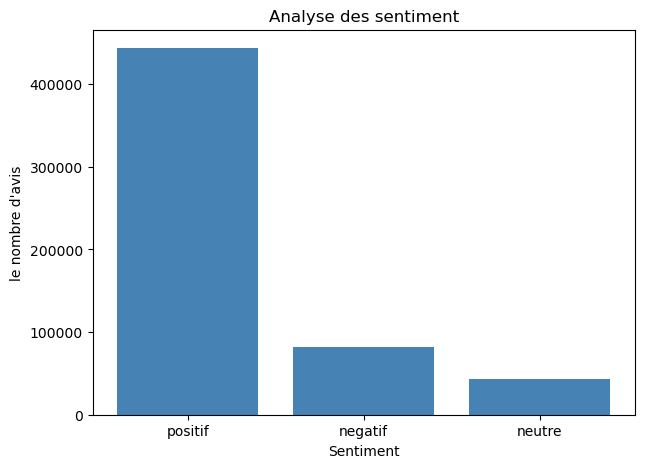

In [29]:
an_sent=df_reel['Sentiment'].value_counts()
plt.figure(figsize=(7,5))
plt.bar(an_sent.index,an_sent.values,color='steelblue')
plt.xlabel("Sentiment")
plt.ylabel('le nombre d\'avis')
plt.title('Analyse des sentiment')
plt.show()

In [30]:
#on enleve les avis neutre 
df_modele=df_reel[df_reel['Sentiment']!='neutre']
df_modele.shape

(525814, 14)

In [31]:
#la methode TF IDF(Transformation en nombre le message)"
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer=TfidfVectorizer(max_features=5000)
X=vectorizer.fit_transform(df_modele['clean_Text'])
Y=df_modele['Sentiment']

In [32]:
print(X.shape)

(525814, 5000)


In [33]:
#Seeparation des donnees en 2 (test et train)
from sklearn.model_selection import train_test_split
Xtrain,Xtest,Ytrain,Ytest=train_test_split(X,Y,test_size=0.2,random_state=42)
print(Xtrain.shape)
print(Xtest.shape)

(420651, 5000)
(105163, 5000)


In [34]:
#Entrainement de model 
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=1000)
model.fit(Xtrain,Ytrain)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [35]:
#Test de model 
from sklearn.metrics import accuracy_score
prediction=model.predict(Xtest)
precision=accuracy_score(Ytest,prediction)
print(f"La precisin du model est:{precision:.2%}")

La precisin du model est:93.50%


In [36]:
from sklearn.metrics import classification_report

print(classification_report(Ytest, prediction))

              precision    recall  f1-score   support

     negatif       0.85      0.71      0.77     16379
     positif       0.95      0.98      0.96     88784

    accuracy                           0.94    105163
   macro avg       0.90      0.84      0.87    105163
weighted avg       0.93      0.94      0.93    105163



In [37]:
#Topic Modeling
#on s'intersse aux avis negatifs
avis_negatifs=df_modele[df_modele['Sentiment']=='negatif']
avis_negatifs.shape

(82037, 14)

In [38]:
#Transfoemation des avis en code
vectorizer_topic=TfidfVectorizer(max_features=1000,stop_words='english')
X_topic=vectorizer_topic.fit_transform(avis_negatifs['clean_Text'])
X_topic.shape

(82037, 1000)

In [39]:
#LA METHODE LDA
from sklearn.decomposition import LatentDirichletAllocation 
lda=LatentDirichletAllocation(n_components=5,random_state=42)
lda.fit(X_topic)

,n_components,5
,doc_topic_prior,None
,topic_word_prior,None
,learning_method,'batch'
,learning_decay,0.7
,learning_offset,10.0
,max_iter,10
,batch_size,128
,evaluate_every,-1
,total_samples,1000000.0
,perp_tol,0.1


In [40]:
mots =vectorizer_topic.get_feature_names_out()

for index, sujet in enumerate(lda.components_):
    top_mots = [mots[i] for i in sujet.argsort()[-10:]]
    print(f"Sujet {index + 1} : {', '.join(top_mots)}")

Sujet 1 : arrived, order, ordered, like, bags, amazon, bag, box, product, br
Sujet 2 : just, tastes, water, drink, flavor, br, like, taste, coffee, tea
Sujet 3 : received, cup, buy, cups, order, price, product, amazon, br, coffee
Sujet 4 : product, chocolate, cookies, salt, good, just, flavor, taste, like, br
Sujet 5 : china, product, cats, eat, treats, cat, dogs, dog, food, br
